# Librerias

In [99]:
"""import optbinning
import ortools

print("OptBinning:", optbinning.__version__)
print("OR-Tools:", ortools.__version__)"""

'import optbinning\nimport ortools\n\nprint("OptBinning:", optbinning.__version__)\nprint("OR-Tools:", ortools.__version__)'

In [100]:
!pip install -r ../requirements.txt

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

# Carga Data

In [102]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_cleaned.csv",
    dtype={

    },
)

In [103]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,period
0,0,0.3,0.986506,-1.0,25.0,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9.0,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,2024-01-01
1,0,0.8,0.617426,-1.0,89.0,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2.0,0,1500.0,0,INTERNET,3.363854,other,1,1,0,2024-01-01
2,0,0.8,0.996707,9.0,14.0,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30.0,0,200.0,0,INTERNET,22.730559,windows,0,1,0,2024-01-01
3,0,0.6,0.475100,11.0,14.0,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1.0,0,200.0,0,INTERNET,15.215816,linux,1,1,0,2024-01-01
4,0,0.9,0.842307,-1.0,29.0,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26.0,0,200.0,0,INTERNET,3.743048,other,0,1,0,2024-01-01


In [104]:
df_data.shape

(1000000, 32)

In [105]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
current_address_months_count        float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                 

In [106]:
# Mostrar todas las filas
pd.set_option("display.max_rows", None)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# No truncar el ancho de la salida
pd.set_option("display.width", None)

# No truncar el contenido de las columnas
pd.set_option("display.max_colwidth", None)

In [107]:
# Quiero que se muestre todos los registros del dataframe y no esto "..."
df_data.isna().sum()

target                              0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

# Nuevas Vars

| Variable | Definition |
|----------|------------|
| **address_total_history** | **Total residential history.** Sum of the months at the current and previous addresses, providing an estimate of the customer's overall residential stability. Higher values indicate longer residential permanence. |
| **address_stability_ratio** | **Residential stability index.** Ratio between the time spent at the current address and the previous address. It helps identify recent address changes or highly mobile customers, which may be associated with higher fraud risk. |
| **digital_identity_score** | **Digital identity strength.** Composite score based on validated phone numbers and the use of a non-free email address. Higher values indicate a stronger and more trustworthy digital identity. |
| **velocity_ratio_6h_24h** | **Recent activity concentration.** Ratio of transaction activity during the last 6 hours relative to the last 24 hours. High values may indicate sudden bursts of activity that are common in fraudulent behavior. |
| **velocity_ratio_24h_4w** | **Recent vs. historical activity ratio.** Compares transaction activity in the last 24 hours with the customer's historical activity over the last four weeks, highlighting unusual behavioral changes. |
| **device_trust_score** | **Device trust level.** Score that combines the number of distinct emails linked to the device, previous fraud associated with the device, and session behavior to estimate device reliability. |
| **email_risk_score** | **Email risk score.** Combines name–email similarity with the number of distinct emails associated with the same date of birth. Higher values indicate potentially suspicious or synthetic digital identities. |
| **credit_limit_income_ratio** | **Credit limit to income ratio.** Measures the relationship between the proposed credit limit and the customer's income, helping identify requests that appear disproportionate to the declared financial capacity. |
| **credit_risk_limit_ratio** | **Credit score–limit consistency.** Relates the customer's credit risk score to the proposed credit limit in order to evaluate whether both variables remain consistent with each other. |
| **customer_stability_score** | **Customer stability score.** Combines banking relationship tenure with residential permanence to represent the customer's overall long-term stability. Higher values suggest more established customers. |
| **contact_consistency** | **Contact consistency.** Indicates whether both home and mobile phone numbers are validated, providing a simple measure of the completeness and reliability of the customer's contact information. |

In [108]:
# ============================================================
# Copia para no modificar el dataframe original
# ============================================================

df_feat = df_data.copy()

# ============================================================
# 1. Address Stability
# ============================================================

# Si prev_address_months_count es -1, se considera que no existe
# dirección anterior y no se suma al historial.
df_feat["address_total_history"] = (
    df_feat["current_address_months_count"].clip(lower=0)
    +
    df_feat["prev_address_months_count"].clip(lower=0)
)

# Si prev_address_months_count es -1 o 0, el denominador será 1
# para evitar división entre cero.
previous_address_denominator = np.where(
    df_feat["prev_address_months_count"] <= 0,
    1,
    df_feat["prev_address_months_count"]
)

df_feat["address_stability_ratio"] = (
    df_feat["current_address_months_count"].clip(lower=0)
    /
    previous_address_denominator
)

# ============================================================
# 2. Digital Identity Score
# ============================================================

# Suma:
# - teléfono fijo válido;
# - teléfono móvil válido;
# - correo no gratuito.
# El resultado toma valores entre 0 y 3.
df_feat["digital_identity_score"] = (
    df_feat["phone_home_valid"].astype(int)
    +
    df_feat["phone_mobile_valid"].astype(int)
    +
    (1 - df_feat["email_is_free"].astype(int))
)

# ============================================================
# 3. Velocity Ratio
# ============================================================

df_feat["velocity_ratio_6h_24h"] = (
    df_feat["velocity_6h"]
    /
    df_feat["velocity_24h"]
)

df_feat["velocity_ratio_24h_4w"] = (
    df_feat["velocity_24h"]
    /
    df_feat["velocity_4w"]
)

# ============================================================
# 4. Device Trust
# ============================================================

df_feat["device_trust_score"] = (
    df_feat["device_distinct_emails_8w"]
    +
    5 * df_feat["device_fraud_count"]
    +
    (1 - df_feat["keep_alive_session"])
)

# ============================================================
# 5. Email Risk
# ============================================================

df_feat["email_risk_score"] = (
    (1 - df_feat["name_email_similarity"])
    *
    df_feat["date_of_birth_distinct_emails_4w"]
)

# ============================================================
# 6. Credit Consistency
# ============================================================

df_feat["credit_limit_income_ratio"] = (
    df_feat["proposed_credit_limit"]
    /
    df_feat["income"]
)

df_feat["credit_risk_limit_ratio"] = (
    (
        df_feat["credit_risk_score"]
        - df_feat["credit_risk_score"].min()
    )
    /
    df_feat["proposed_credit_limit"]
)

# ============================================================
# 7. Customer Stability
# ============================================================

# Los valores -1 se convierten en 0 porque representan
# ausencia de antigüedad registrada o condición no aplicable.
df_feat["customer_stability_score"] = (
    df_feat["bank_months_count"].clip(lower=0)
    +
    df_feat["current_address_months_count"].clip(lower=0)
)

# ============================================================
# 8. Contact Consistency
# ============================================================

# Será 1 únicamente cuando ambos teléfonos sean válidos.
df_feat["contact_consistency"] = (
    df_feat["phone_home_valid"].astype(int)
    *
    df_feat["phone_mobile_valid"].astype(int)
)

# ============================================================
# Variables nuevas
# ============================================================

nuevas_variables = [
    "address_total_history",
    "address_stability_ratio",
    "digital_identity_score",
    "velocity_ratio_6h_24h",
    "velocity_ratio_24h_4w",
    "device_trust_score",
    "email_risk_score",
    "credit_limit_income_ratio",
    "credit_risk_limit_ratio",
    "customer_stability_score",
    "contact_consistency"
]

In [109]:
df_feat.describe(include="all")[nuevas_variables].T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
address_total_history,1000000.0,NaN,NaN,NaN,104.249071,87.404036,0.000000,41.000000,70.000000,145.000000,720.000000
address_stability_ratio,1000000.0,NaN,NaN,NaN,80.668216,90.271094,0.000000,1.181818,49.000000,125.000000,428.000000
digital_identity_score,1000000.0,NaN,NaN,NaN,1.776867,0.709465,0.000000,1.000000,2.000000,2.000000,3.000000
velocity_ratio_6h_24h,1000000.0,NaN,NaN,NaN,1.209313,0.577614,-0.058746,0.806072,1.215435,1.558393,8.620877
velocity_ratio_24h_4w,1000000.0,NaN,NaN,NaN,0.986199,0.268216,0.232317,0.791944,0.956378,1.154253,3.003246
device_trust_score,1000000.0,NaN,NaN,NaN,1.441365,0.531963,-1.000000,1.000000,1.000000,2.000000,3.000000
email_risk_score,1000000.0,NaN,NaN,NaN,4.778235,4.001045,0.000000,1.683395,3.716734,6.869775,36.339294
credit_limit_income_ratio,1000000.0,NaN,NaN,NaN,1505.609337,2403.074782,211.111111,285.714286,666.666667,2000.000000,21000.000000
credit_risk_limit_ratio,1000000.0,NaN,NaN,NaN,0.986763,0.503015,0.000000,0.490000,1.130000,1.390000,2.690000
customer_stability_score,1000000.0,NaN,NaN,NaN,97.910521,89.879840,0.000000,33.000000,66.000000,142.000000,456.000000


# IV - WoE NUEVAS VARS

In [110]:
from optbinning import OptimalBinning, BinningProcess

In [111]:
def plot_analisis(data, analysis_type, analysis_columns, target, umbral_iv):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)

    # Función para formatear los bins
    def format_bin(bin_value):
        if isinstance(bin_value, tuple):  # Si es un intervalo (tupla)
            return f"[{round(bin_value[0], 4)}, {round(bin_value[1], 4)})"
        elif isinstance(bin_value, (int, float)):  # Si es un número
            return round(bin_value, 4)
        else:  # Si es una cadena (por ejemplo, 'Missing' o 'Special')
            return bin_value

    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()

        # Formatear los bins a 4 decimales
        if analysis_type == 'numerical':
            tabla['Bin'] = tabla['Bin'].apply(format_bin)

        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)

        print('variable ' + columnName)
        print('---------------------------------------------------------')

        # Imprimir la tabla con 4 decimales
        with pd.option_context('display.float_format', '{:.4f}'.format):
            print(tabla)

        binning_table.plot('event_rate')

    df = pd.DataFrame(pd.Series(list1, index=list2))
    df = df.rename(columns={0: 'IV'})
    df = df[df['IV'] > umbral_iv].sort_values(by='IV', axis=0, ascending=False).reset_index()

    return df

In [112]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [113]:
# ESTO ES PARA DEVOLVER EL WOE PARA LAS CATEGÓRICAS MÁS QUE NADA
def woe_analysis(data, analysis_type, analysis_columns, target):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)
    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()
        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)
    return tabla_f

In [114]:
# Función para aplicar WoE
def woe_transform(data_cat, columnas_interes, dic_woe):
    """
    Aplica la transformación WoE a un conjunto de datos categóricos.

    Parámetros:
    - data_cat: DataFrame con las variables categóricas.
    - columnas_interes: Lista de columnas categóricas a transformar.
    - dic_woe: Diccionario con los valores de WoE {variable: {categoria: WoE}}.

    Retorna:
    - DataFrame con las variables transformadas a WoE.
    """
    data_cat = data_cat.copy()  # 🔥 Evita modificar el DataFrame original

    for columna in columnas_interes:
        if columna in dic_woe:  # ✅ Verifica si la columna tiene WoE en el diccionario
            data_cat['woe_' + columna] = data_cat[columna].map(dic_woe[columna])
        else:
            print(f"⚠️ Advertencia: No se encontró WoE para la columna '{columna}', se dejará como NaN.")

    columns = ['woe_' + k for k in columnas_interes if 'woe_' + k in data_cat]  # ✅ Solo columnas existentes

    return data_cat[columns]  # ✅ Devuelve solo las columnas transformadas

In [115]:
def selVarWoeIv(data = pd.DataFrame({}), varModel = [], varString = [], exclude = [], target = '', show_plots = 'all', show_variables = 'all',summary_table = True):
    """
    df: dataframe
    varModel: variables del df
    varString: variables del df que son categoricos
    target: columna objetivo
    """
    df = data.copy()
    numRows = df.shape[0]
    numCiclos = range(2,20)
    if (numRows<12):numCiclos = range(2,numRows)
    numTarget = df[target].sum()
    columnNameTarget = target
    efec = numTarget/numRows
    listTransformationWoe = {}
    listIv = {}
    cortes = {}
    varModel = [var for var in varModel if var not in exclude]
    varString = [var for var in varString if var not in exclude]
    error_cols_nn = []
    for columnName in varModel:
        path_changed = False
        print('\n----------------------------')
        print("****\t" + columnName +"\t****")
        print('----------------------------\n')
        listTestIv = []
        tempIv = [0]
        listColumns = []
        iter = 0
        categ = []
        if (columnName not in varString):
            for i in numCiclos:
                percents = [np.round(x / i, 2) for x in range(1, i)]
                listPercent = np.percentile(df[columnName],np.array(percents)*100)
                listPercent = np.round(listPercent,4)
                listPercent = np.insert(listPercent,0,- 999999999999)
                listPercent = np.insert(listPercent, len(listPercent), 999999999999)
                listPercent = np.round(listPercent, 4)
                columnClassPercet = np.zeros(len(df[columnName]))
                columnClassOrden = np.zeros(len(df[columnName]))

                for j in range(len(listPercent)-1):
                    prueba = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * listPercent[j+1]
                    columnClassPercet = prueba + columnClassPercet
                    order = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * (j+1)
                    columnClassOrden = order + columnClassOrden

                columnClassPercet = np.round(columnClassPercet, 4).astype(str)
                columnClassPercet = np.where(columnClassPercet.str.contains('999999999999'), f'>{listPercent[-2]}', columnClassPercet)
                columnClassOrden = columnClassOrden - 1
                listPercent = listPercent[1:-1]
                listPercent = np.unique(listPercent)

                df['range'] = columnClassPercet
                df['columnClassOrden'] = columnClassOrden
                dfTemp = df.groupby(['range','columnClassOrden'])\
                           .agg(leads = (columnNameTarget, 'count'),
                                target = (columnNameTarget, 'sum'),
                                pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                                efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                                pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                                pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                               ).reset_index()
                numerador = (dfTemp['target'] + 0.5) / numTarget
                denominador = (dfTemp['leads'] - dfTemp['target'] + 0.5)/(numRows - numTarget)
                dfTemp['res2'] = np.log(numerador / denominador)
                dfTemp['res1'] = np.log(dfTemp["pctTarget"]/dfTemp["pctNoTarget"])
                dfTemp['woe'] = np.where(dfTemp["pctTarget"]/dfTemp["pctNoTarget"]<=0, dfTemp['res2'], dfTemp['res1'])
                dfTemp['iv'] = np.where(((dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe']).isna(),
                                              0,
                                              (dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe'])
                dfTemp.drop(columns = ['res1','res2'], inplace = True)
                dfTemp = dfTemp.sort_values('columnClassOrden')

                iv =  [round(dfTemp[~dfTemp['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                       dfTemp[(dfTemp['columnClassOrden']>=0)&(~dfTemp['iv'].isin([np.inf, -np.inf]))]['pctLeads'].min()]

                if iv[1] >= 0.01:
                    if (iv[0] > np.max(tempIv)):
                        listTestIv.append(iv[0])
                        dfFin = dfTemp.drop(columns = ['columnClassOrden'])
                        ivOpt = iv[0]
                        per = dfFin['range'].tolist()
                        n = dfFin.shape[0]
                        labelIv = 'percentiles'
                        dictDataFrame = dfFin.set_index('range').T.to_dict('list')

                        columnTransform = [[],[]]
                        columnTransform[0] = per
                        for r in per:
                            columnTransform[1].append(np.round(dictDataFrame[r][6],4))

                        categ.append(len(per)+1)
                        tempIv.append(iv[0])
                        iter = iter + 1

            if(iter == 0):
                columnTransform = ""
                ivOpt = 0
                per = []
                labelIv = 'percentiles'
                listTestIv.append(0)
                dfFin = pd.DataFrame([[0,0,0,0,0]], columns=['range','leads','target','efecTarget','woe'])
                n = dfFin.shape[0]
                path_changed = True


        if ((columnName in varString) or (path_changed)):
            if path_changed:
                print('VAR "', columnName, '" CHANGED TO CATEGORICAL')
                data[columnName+'_orig'] = data[columnName].copy()
                if 'varpor' in columnName:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else (-1 if x<0.0 else 0)))
                                        .astype(str)
                                       )
                else:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else 0))
                                        .astype(str)
                                       )

                error_cols_nn.append(columnName)
                df = data.copy()

            dfFin = df.groupby(columnName)\
                      .agg(leads = (columnNameTarget, 'count'),
                           target = (columnNameTarget, 'sum'),
                           pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                           efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                           pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                           pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                           ).reset_index()
            dfFin.rename(columns = {columnName:'range'}, inplace = True)
            numerador = (dfFin['target'] + 0.5) / numTarget
            denominador = (dfFin['leads'] - dfFin['target'] + 0.5)/(numRows - numTarget)
            dfFin['res2'] = np.log(numerador / denominador)
            dfFin['res1'] = np.log(dfFin["pctTarget"]/dfFin["pctNoTarget"])
            dfFin['woe'] = np.where(dfFin["pctTarget"]/dfFin["pctNoTarget"]<=0, dfFin['res2'], dfFin['res1'])
            dfFin['iv'] = np.where(((dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe']).isna(),
                                          0,
                                          (dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe'])
            dfFin.drop(columns = ['res1','res2'], inplace = True)

            iv =  [round(dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                   dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['pctLeads'].min()]
            ivOpt=iv[0]
            n = dfFin.shape[0]
            per = [0]
            labelIv = 'categorias'
            categ.append(n)
            listTestIv.append(ivOpt)
            dictDataFrame = dfFin.set_index('range').T.to_dict('list')
            listKeys = list(dictDataFrame.keys())

            columnTransform = [[],[]]
            columnTransform[0] = listKeys
            for j in range(len(listKeys)):
                columnTransform[1].append(dictDataFrame[listKeys[j]][6])

        listTransformationWoe[columnName] = columnTransform
        listIv[columnName] = ivOpt
        pp1 = dfFin[['range','leads','target','efecTarget','woe']]
        listiv = dict(sorted(listIv.items(), key=lambda item: item[1]))
        ejeHor = list(pp1['range'])

        if show_plots == 'all':
            sIv = pd.Series(listTestIv)
            plt.subplot(1,2,1)
            plt.rcParams['figure.figsize'] = (9, 4)
            plt.plot(sIv, marker='*')
            plt.xticks(range(len(categ)),categ)
            plt.title('Gráfico IV')
            plt.xlabel(labelIv)

            plt.subplot(1,2,2)
            pp1['woe'].plot(kind='bar',alpha=0.5, stacked=True, color='k', label='woe')
            plt.xticks(range(len(ejeHor)),ejeHor,rotation=90)
            plt.title('Gráfico WOE')
            plt.xlabel('categorias de variable')

            fig = plt.figure()
            ax = fig.add_subplot(111)
            pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
            pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
            plt.legend(loc = (1.1,0.55), frameon = False)
            plt.xlabel('categorias de variable')
            plt.xticks(range(len(ejeHor)),ejeHor)
            ax2 = ax.twinx()
            xHor = np.arange(len(pp1['range']))
            ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
            ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
            plt.legend( loc = (1.1,0.4), frameon = False)
            fig.autofmt_xdate(rotation=90)
            plt.title(columnName.upper())
            plt.show()

        elif show_plots == 'principal':
            if show_variables == 'principal':
                if ivOpt>0.02:
                    fig = plt.figure()
                    ax = fig.add_subplot(111)
                    pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                    pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                    plt.legend(loc = (1.1,0.55), frameon = False)
                    plt.xlabel('categorias de variable')
                    plt.xticks(range(len(ejeHor)),ejeHor)
                    ax2 = ax.twinx()
                    xHor = np.arange(len(pp1['range']))
                    ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                    ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                    plt.legend( loc = (1.1,0.4), frameon = False)
                    fig.autofmt_xdate(rotation=90)
                    plt.title(columnName.upper())
                    plt.show()
                else:
                    pass
            else:
                fig = plt.figure()
                ax = fig.add_subplot(111)
                pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                plt.legend(loc = (1.1,0.55), frameon = False)
                plt.xlabel('categorias de variable')
                plt.xticks(range(len(ejeHor)),ejeHor)
                ax2 = ax.twinx()
                xHor = np.arange(len(pp1['range']))
                ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                plt.legend( loc = (1.1,0.4), frameon = False)
                fig.autofmt_xdate(rotation=90)
                plt.title(columnName.upper())
                plt.show()
        elif show_plots == 'nothing':
            pass

        if summary_table == True:
            if (columnName not in varString):
                print("\nCon "+str(len(per)+1)+" percentiles: "+ str(per))
                print("Se obtuvo " + str(n) + " categorias")
            else:
                print("\nSe obtuvo " + str(n) + " categorias fijas: ")
            print("iv óptimo: " + str(ivOpt))
            display(dfFin)
            if (len(per) == 0):print('OBSERVACIÓN:\n¡NO SE ENCONTRARON categorías relevantes!\n Podría considerarlo como VARIABLE CATEGÓRICA')
        else:
            pass

        dfFin2 = dfFin[~dfFin['iv'].isin([np.inf, -np.inf])].sort_values(by = 'efecTarget', ascending = False)
        cortes[columnName] = list(dfFin2[dfFin2['efecTarget'] >= efec]['range'])

    plt.figure(figsize = (6,8))
    plt.barh(list(listiv.keys()),list(listiv.values()))
    plt.axvline(0.02, color='red', linestyle = '--') #cambiar linea bsae
    plt.title('Feature Importance')
    plt.show()

    df_importancia = pd.DataFrame(list(listIv.items()), columns = ['variable','iv']).sort_values(by = 'iv', ascending = False).reset_index(drop = True)
    df_cortes = pd.DataFrame(list(cortes.items()), columns = ['variable','corte'])
    df_final = df_importancia.merge(df_cortes, on = 'variable', how = 'left')

    return  df_final, listiv, listTransformationWoe, error_cols_nn


## IV WOE

In [116]:
df_numeric = df_feat[nuevas_variables + ["target"]]

columnas_numericas = nuevas_variables

C:\Users\Renzo\AppData\Local\Temp\ipykernel_31828\566123806.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[target] = data[target].astype(int)


variable address_total_history
---------------------------------------------------------
                     Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 38.50)   224675     0.2247     223510   1165      0.0052   
1         [38.50, 45.50)    81129     0.0811      80586    543      0.0067   
2         [45.50, 51.50)    57019     0.0570      56518    501      0.0088   
3         [51.50, 60.50)    73737     0.0737      72932    805      0.0109   
4         [60.50, 68.50)    56271     0.0563      55620    651      0.0116   
5         [68.50, 93.50)   106682     0.1067     105181   1501      0.0141   
6        [93.50, 123.50)    98214     0.0982      96603   1611      0.0164   
7       [123.50, 148.50)    59076     0.0591      58017   1059      0.0179   
8       [148.50, 177.50)    52484     0.0525      51653    831      0.0158   
9       [177.50, 297.50)   140071     0.1401     138329   1742      0.0124   
10         [297.50, inf)    50642     0.0506      500

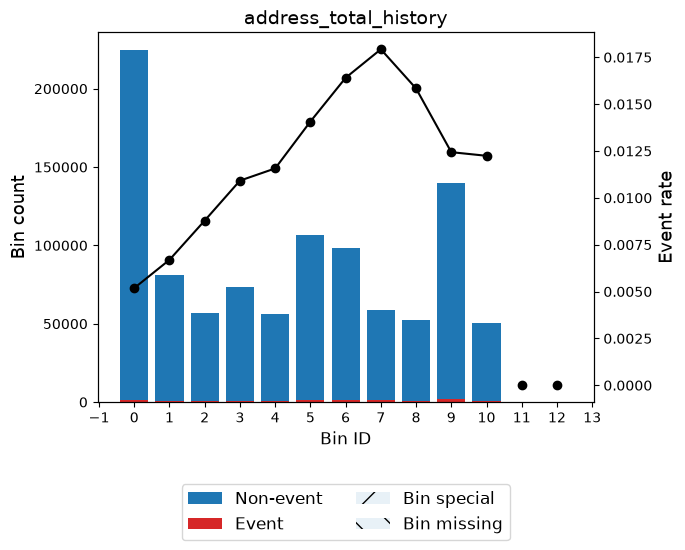

variable address_stability_ratio
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 0.07)    51727     0.0517      51505    222      0.0043   
1         [0.07, 0.19)    70593     0.0706      70390    203      0.0029   
2         [0.19, 0.55)    86492     0.0865      86285    207      0.0024   
3         [0.55, 1.77)    57149     0.0571      56978    171      0.0030   
4        [1.77, 31.62)   103366     0.1034     102693    673      0.0065   
5       [31.62, 38.83)    51733     0.0517      51366    367      0.0071   
6       [38.83, 46.62)    61090     0.0611      60551    539      0.0088   
7       [46.62, 54.50)    50431     0.0504      49756    675      0.0134   
8       [54.50, 65.50)    52624     0.0526      51767    857      0.0163   
9         [65.50, inf)   414795     0.4148     407680   7115      0.0172   
10             Special        0     0.0000          0      0      0.0000 

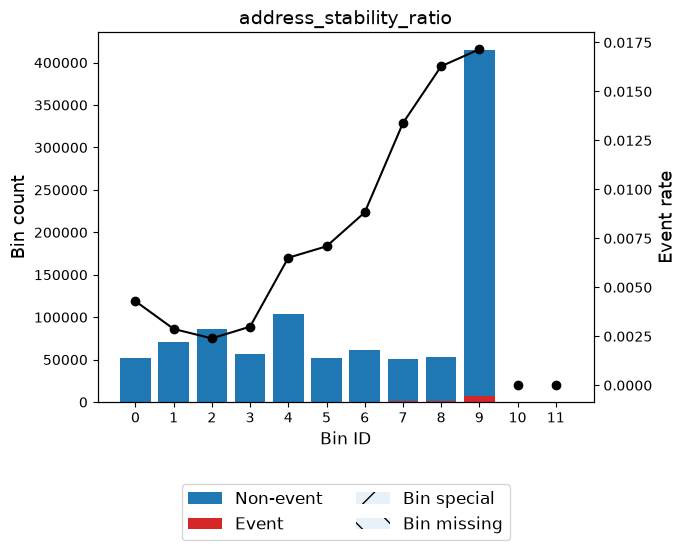

variable digital_identity_score
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 1.50)   366395     0.3664     360047   6348      0.0173   
1       [1.50, 2.50)   479475     0.4795     475365   4110      0.0086   
2        [2.50, inf)   154130     0.1541     153559    571      0.0037   
3            Special        0     0.0000          0      0      0.0000   
4            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.4580 0.0969 0.0120  
1       0.2545 0.0275 0.0034  
2       1.0983 0.1137 0.0135  
3       0.0000 0.0000 0.0000  
4       0.0000 0.0000 0.0000  
Totals         0.2380 0.0290  


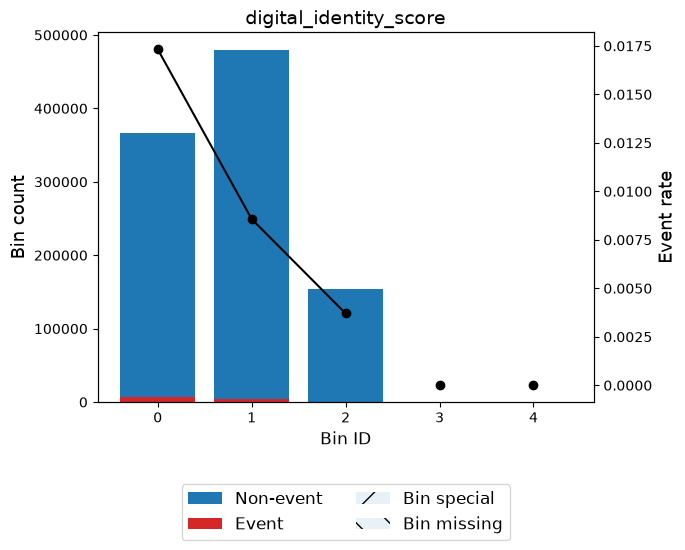

variable velocity_ratio_6h_24h
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.37)    73116     0.0731      72049   1067      0.0146   
1       [0.37, 0.54)    63206     0.0632      62360    846      0.0134   
2       [0.54, 0.66)    50185     0.0502      49596    589      0.0117   
3       [0.66, 1.14)   259263     0.2593     256289   2974      0.0115   
4       [1.14, 1.61)   338054     0.3381     334485   3569      0.0106   
5       [1.61, 1.95)   136958     0.1370     135668   1290      0.0094   
6        [1.95, inf)    79218     0.0792      78524    694      0.0088   
7            Special        0     0.0000          0      0      0.0000   
8            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.2836 0.0068 0.0008  
1      -0.1960 0.0027 0.0003  
2  

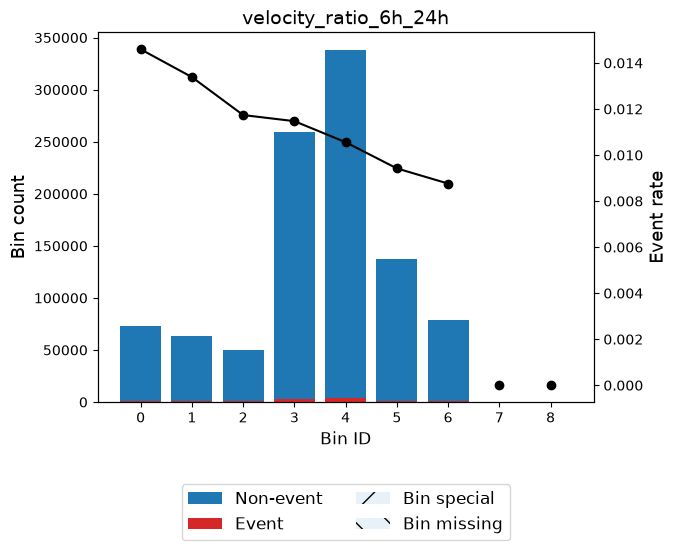

variable velocity_ratio_24h_4w
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.63)    64584     0.0646      63741    843      0.0131   
1       [0.63, 1.18)   721019     0.7210     712941   8078      0.0112   
2       [1.18, 1.24)    55287     0.0553      54788    499      0.0090   
3       [1.24, 1.34)    77383     0.0774      76644    739      0.0095   
4        [1.34, inf)    81727     0.0817      80857    870      0.0106   
5            Special        0     0.0000          0      0      0.0000   
6            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.1705 0.0020 0.0003  
1      -0.0159 0.0002 0.0000  
2       0.2025 0.0021 0.0003  
3       0.1455 0.0015 0.0002  
4       0.0358 0.0001 0.0000  
5       0.0000 0.0000 0.0000  
6       0.0000 0.0000 0.000

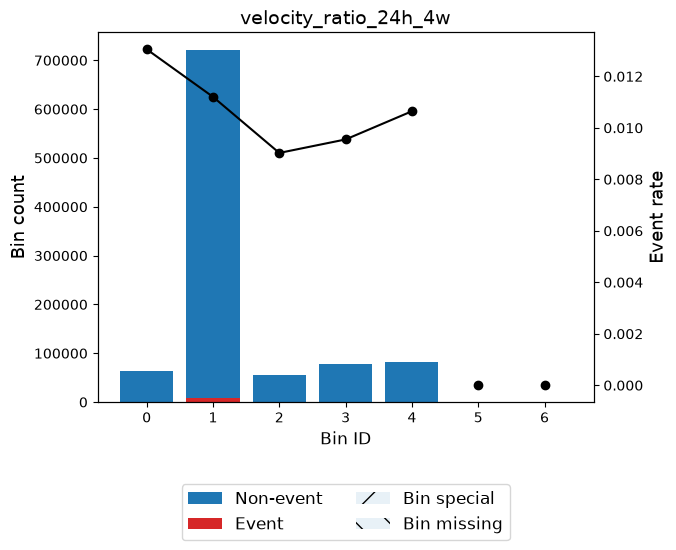

variable device_trust_score
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 1.50)   574852     0.5749     571122   3730      0.0065   
1        [1.50, inf)   425148     0.4251     417849   7299      0.0172   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.5351 0.1280 0.0158  
1      -0.4488 0.1074 0.0133  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.2354 0.0291  


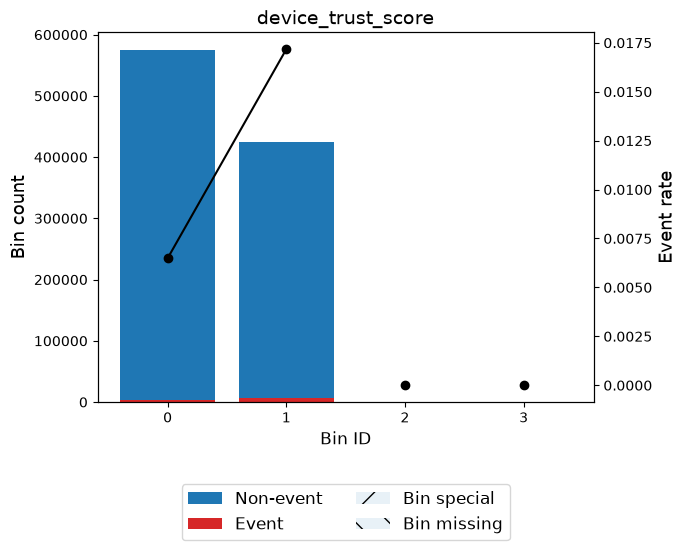

variable email_risk_score
---------------------------------------------------------
                  Bin    Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 0.35)    50033     0.0500      49469    564      0.0113   
1        [0.35, 1.04)    98766     0.0988      97310   1456      0.0147   
2        [1.04, 1.96)   144112     0.1441     142327   1785      0.0124   
3        [1.96, 8.32)   532684     0.5327     527128   5556      0.0104   
4       [8.32, 10.26)    71343     0.0713      70645    698      0.0098   
5        [10.26, inf)   103062     0.1031     102092    970      0.0094   
6             Special        0     0.0000          0      0      0.0000   
7             Missing        0     0.0000          0      0      0.0000   
Totals                 1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.0221 0.0000 0.0000  
1      -0.2939 0.0099 0.0012  
2      -0.1174 0.0021 0.0003  
3       0.0564 0.0017 0.0002  
4       0.

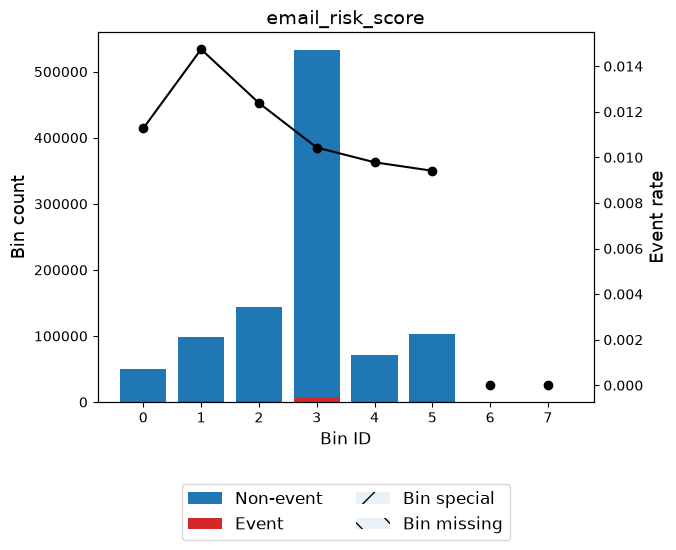

variable credit_limit_income_ratio
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0           (-inf, 227.78)   113266     0.1133     111726   1540      0.0136   
1         [227.78, 256.25)    84442     0.0844      83815    627      0.0074   
2         [256.25, 292.86)    63816     0.0638      63410    406      0.0064   
3         [292.86, 410.00)   105920     0.1059     105281    639      0.0060   
4         [410.00, 534.72)    53494     0.0535      53198    296      0.0055   
5        [534.72, 1075.00)   185855     0.1859     184187   1668      0.0090   
6       [1075.00, 2105.56)   253688     0.2537     250227   3461      0.0136   
7           [2105.56, inf)   139519     0.1395     137127   2392      0.0171   
8                  Special        0     0.0000          0      0      0.0000   
9                  Missing        0     0.0000          0      0      0.0000   
Totals                     

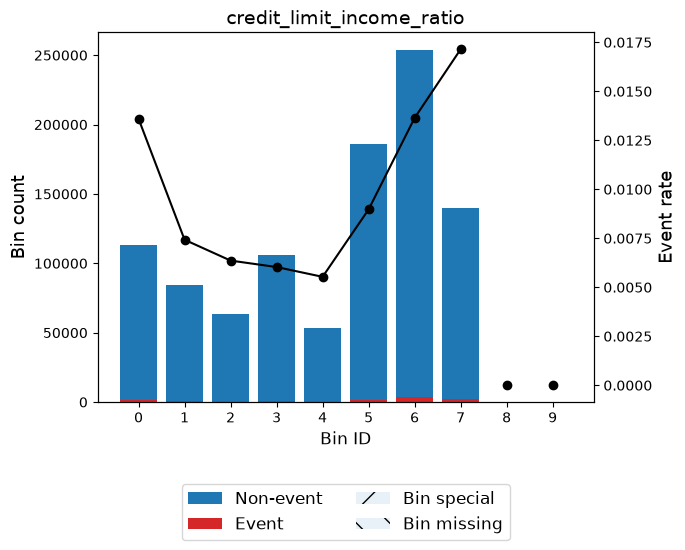

variable credit_risk_limit_ratio
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.24)    52140     0.0521      50833   1307      0.0251   
1       [0.24, 0.35)   135288     0.1353     132286   3002      0.0222   
2       [0.35, 0.50)    63470     0.0635      62641    829      0.0131   
3       [0.50, 0.89)   151363     0.1514     149888   1475      0.0097   
4       [0.89, 1.31)   255887     0.2559     254216   1671      0.0065   
5       [1.31, 1.42)   129570     0.1296     128766    804      0.0062   
6       [1.42, 1.47)    51619     0.0516      51334    285      0.0055   
7       [1.47, 1.54)    51023     0.0510      50693    330      0.0065   
8       [1.54, 1.68)    58140     0.0581      57629    511      0.0088   
9        [1.68, inf)    51500     0.0515      50685    815      0.0158   
10           Special        0     0.0000          0      0      0.0000   
11           Missing 

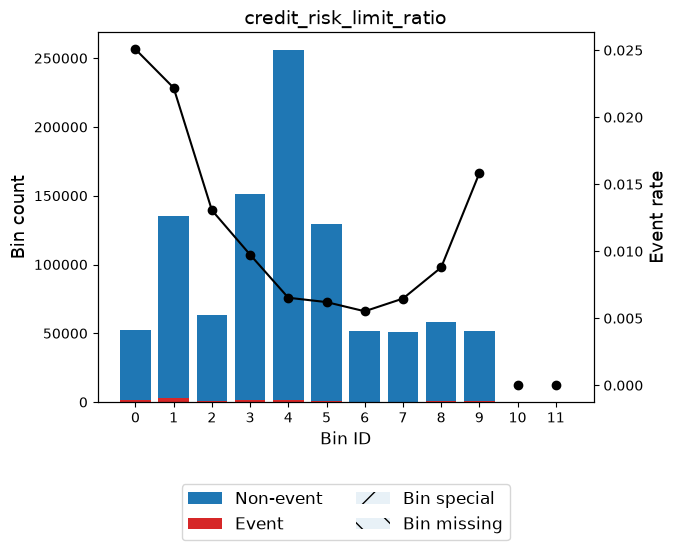

variable customer_stability_score
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 8.50)    66937     0.0669      66674    263      0.0039   
1        [8.50, 15.50)    60552     0.0606      60325    227      0.0037   
2       [15.50, 25.50)    59568     0.0596      59382    186      0.0031   
3       [25.50, 37.50)   106400     0.1064     105937    463      0.0044   
4       [37.50, 46.50)    78733     0.0787      78287    446      0.0057   
5       [46.50, 55.50)    63302     0.0633      62695    607      0.0096   
6       [55.50, 64.50)    55833     0.0558      55202    631      0.0113   
7       [64.50, 73.50)    51088     0.0511      50471    617      0.0121   
8       [73.50, 90.50)    73181     0.0732      71972   1209      0.0165   
9         [90.50, inf)   384406     0.3844     378026   6380      0.0166   
10             Special        0     0.0000          0      0      0.0000

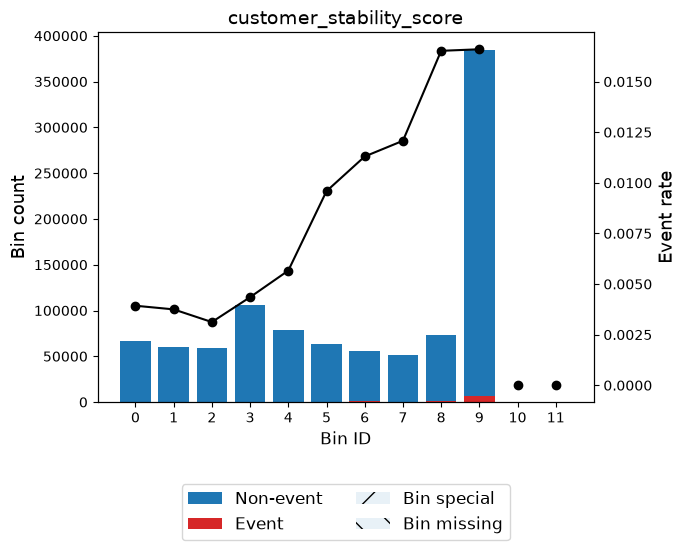

variable contact_consistency
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   671015     0.6710     661748   9267      0.0138   
1        [0.50, inf)   328985     0.3290     327223   1762      0.0054   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.2277 0.0390 0.0049  
1       0.7281 0.1246 0.0152  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.1635 0.0201  


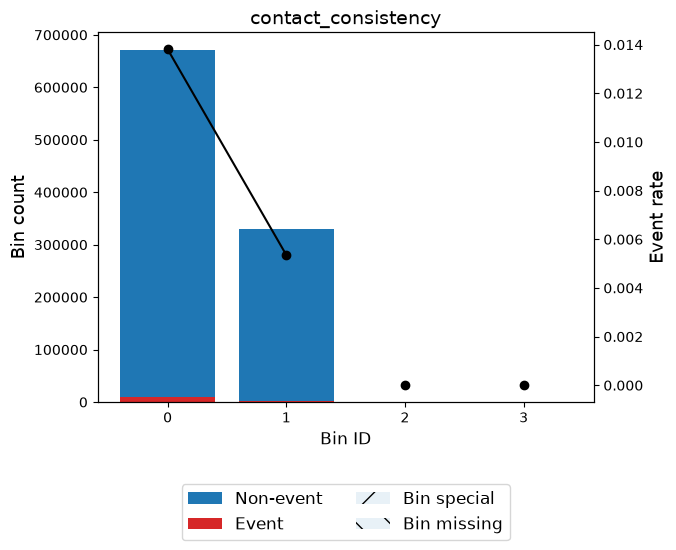

In [117]:
df_result = plot_analisis(
    df_numeric,
    "numerical",
    columnas_numericas,
    "target",
    0.09
)

In [118]:
df_result

,index,IV
0,address_stability_ratio,0.412547
1,customer_stability_score,0.329117
2,credit_risk_limit_ratio,0.288376
3,digital_identity_score,0.238047
4,device_trust_score,0.235418
5,address_total_history,0.167112
6,contact_consistency,0.163543
7,credit_limit_income_ratio,0.135567


# Juntamos data

In [119]:
df_data = pd.concat(
    [df_data, df_feat[nuevas_variables]],
    axis=1
)

In [120]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,period,address_total_history,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,customer_stability_score,contact_consistency
0,0,0.3,0.986506,-1.0,25.0,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9.0,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,2024-01-01,25.0,25.000000,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,34.0,0
1,0,0.8,0.617426,-1.0,89.0,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2.0,0,1500.0,0,INTERNET,3.363854,other,1,1,0,2024-01-01,89.0,89.000000,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,91.0,1
2,0,0.8,0.996707,9.0,14.0,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30.0,0,200.0,0,INTERNET,22.730559,windows,0,1,0,2024-01-01,23.0,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,44.0,0
3,0,0.6,0.475100,11.0,14.0,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1.0,0,200.0,0,INTERNET,15.215816,linux,1,1,0,2024-01-01,25.0,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,15.0,0
4,0,0.9,0.842307,-1.0,29.0,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26.0,0,200.0,0,INTERNET,3.743048,other,0,1,0,2024-01-01,29.0,29.000000,3,1.483498,0.862528,2,0.946159,222.222222,1.305,55.0,1


# Análisis de correlaciones

## Pearson

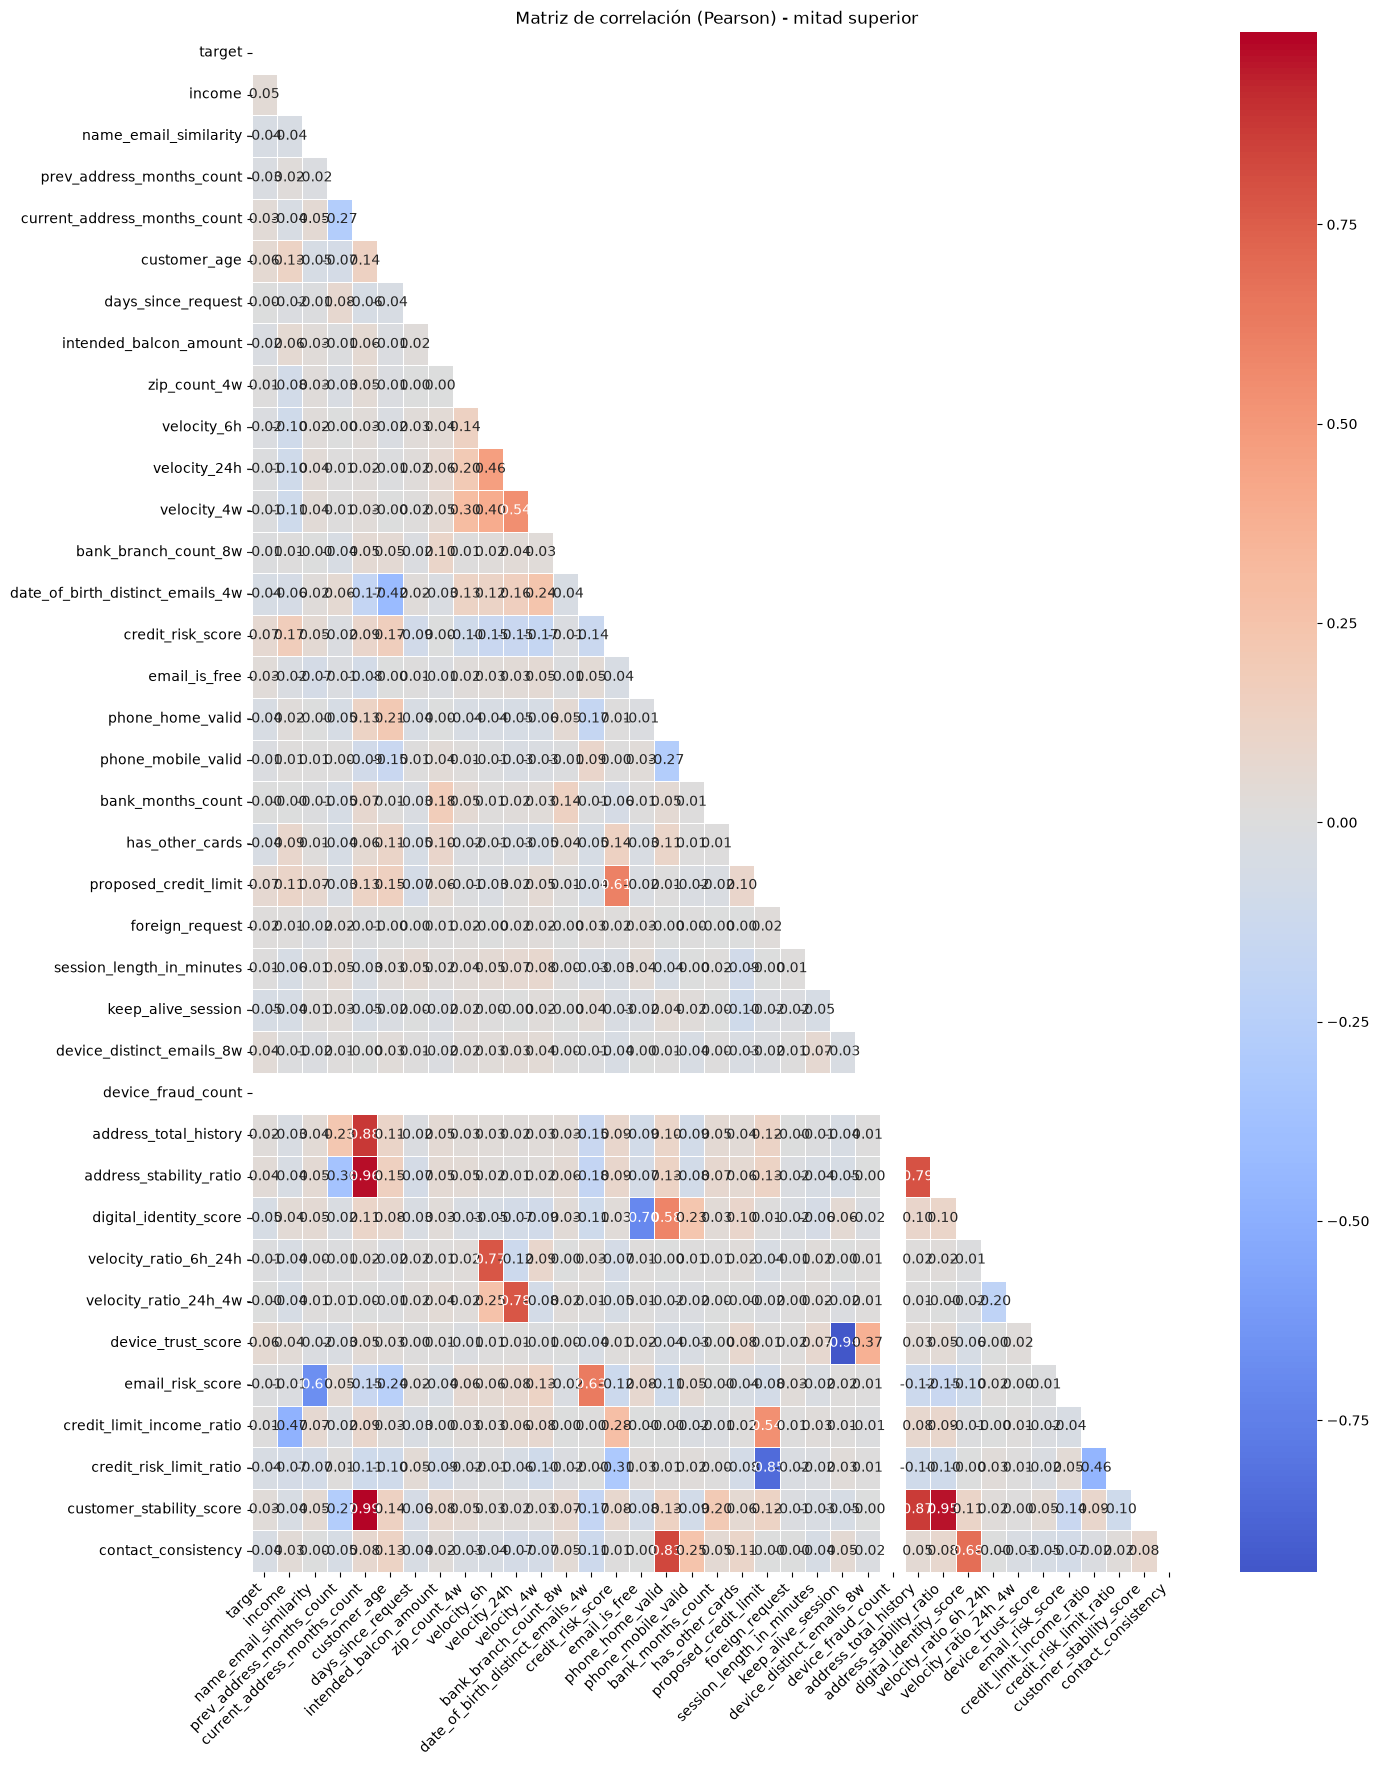

In [121]:
# Matriz de correlación de Pearson con el target incluido y mostrando solo la mitad superior
numeric_df = df_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    corr_matrix = numeric_df.corr(method='pearson')
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    corr_matrix = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool))

    plt.figure(figsize=(15, 20))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        cmap='coolwarm',
        center=0,
        fmt='.2f',
        linewidths=0.5
    )
    plt.title('Matriz de correlación (Pearson) - mitad superior')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


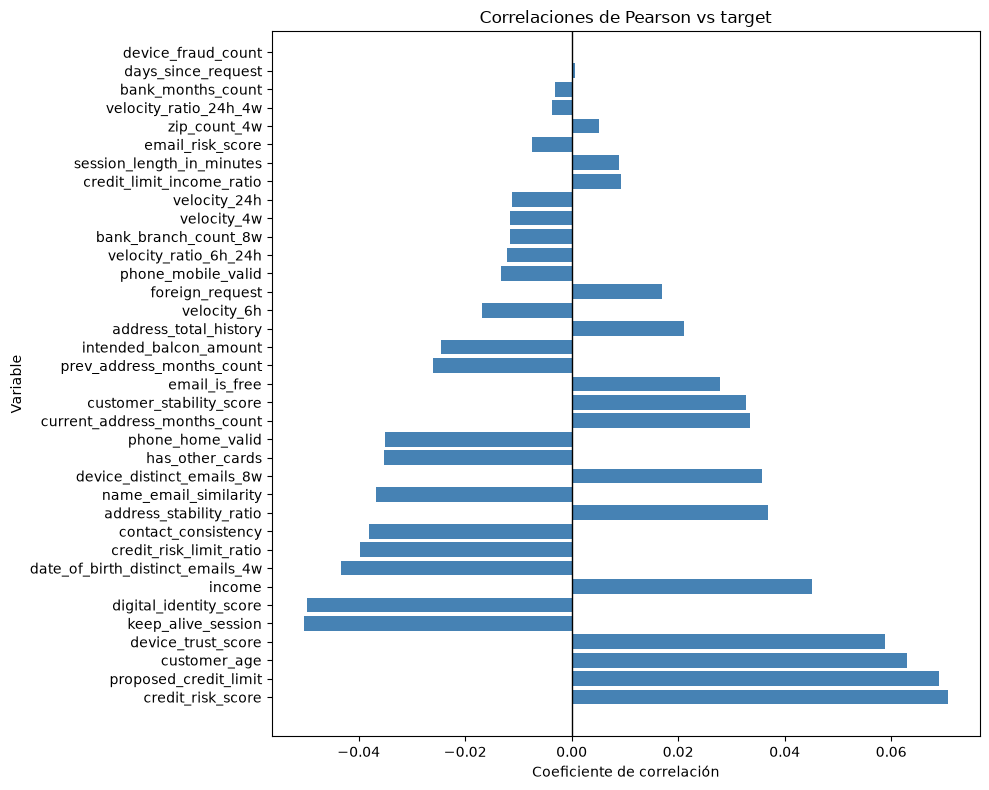

In [122]:
# Correlaciones de Pearson entre variables numéricas y el target
numeric_df = df_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    features = [col for col in numeric_df.columns if col != 'target']
    correlations = pd.DataFrame(
        {'correlacion': [numeric_df[col].corr(numeric_df['target'], method='pearson') for col in features]},
        index=features
    ).sort_values('correlacion', key=lambda x: x.abs(), ascending=False)

    plt.figure(figsize=(10, 8))
    plt.barh(correlations.index, correlations['correlacion'], color='steelblue')
    plt.axvline(0, color='black', linewidth=1)
    plt.title('Correlaciones de Pearson vs target')
    plt.xlabel('Coeficiente de correlación')
    plt.ylabel('Variable')
    plt.tight_layout()
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

### Semaforización

In [123]:
import numpy as np
import pandas as pd
from typing import Optional


# Función para mostrar 3 niveles de correlación
def categorizar_correlaciones(
    corr: pd.DataFrame,
    usar_abs: bool = True,
    imprimir: bool = True,
    top_por_categoria: Optional[int] = None
):

    mat = corr.abs() if usar_abs else corr.copy()

    mask = np.triu(np.ones(mat.shape, dtype=bool), k=1)
    pares = mat.where(mask).stack().reset_index()
    pares.columns = ["var_1", "var_2", "corr"]

    pares["corr_pct"] = pares["corr"] * 100

    bins = [-0.0000001, 10, 60, 100]
    labels = ["Aceptable", "Medio", "Alto"]

    pares["categoria"] = pd.cut(
        pares["corr_pct"],
        bins=bins,
        labels=labels,
        right=True
    )

    pares = pares.sort_values(
        "corr",
        ascending=False
    ).reset_index(drop=True)

    salida = {}

    for cat in ["Alto", "Medio", "Aceptable"]:

        df_cat = pares.loc[
            pares["categoria"] == cat,
            ["var_1", "var_2", "corr", "corr_pct"]
        ].copy()

        df_cat["corr_pct"] = df_cat["corr_pct"].round(2)

        if top_por_categoria is not None:
            df_cat = df_cat.head(top_por_categoria)

        salida[cat] = df_cat

    if imprimir:

        signo = "|corr|" if usar_abs else "corr"

        print(f"\n=== Clasificación por {signo} (pares únicos, sin duplicados) ===")

        for cat in ["Alto", "Medio", "Aceptable"]:

            df_cat = salida[cat]

            print(f"\n--- {cat} ({len(df_cat)} pares) ---")

            if df_cat.empty:
                print("No hay pares en esta categoría.")

            else:

                for _, r in df_cat.iterrows():
                    print(
                        f"{r['var_1']} vs {r['var_2']}: {r['corr_pct']}%"
                    )

    return salida

In [124]:
df_num = df_data.select_dtypes(include=[np.number])
df_corr = df_num.corr(method='pearson')

#salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True, top_por_categoria=5)
salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True)


=== Clasificación por |corr| (pares únicos, sin duplicados) ===

--- Alto (16 pares) ---
current_address_months_count vs customer_stability_score: 99.13%
current_address_months_count vs address_stability_ratio: 96.27%
address_stability_ratio vs customer_stability_score: 95.5%
keep_alive_session vs device_trust_score: 94.06%
current_address_months_count vs address_total_history: 87.59%
address_total_history vs customer_stability_score: 86.66%
proposed_credit_limit vs credit_risk_limit_ratio: 84.82%
phone_home_valid vs contact_consistency: 82.78%
address_total_history vs address_stability_ratio: 79.46%
velocity_24h vs velocity_ratio_24h_4w: 77.91%
velocity_6h vs velocity_ratio_6h_24h: 77.28%
email_is_free vs digital_identity_score: 69.94%
digital_identity_score vs contact_consistency: 68.26%
name_email_similarity vs email_risk_score: 67.33%
date_of_birth_distinct_emails_4w vs email_risk_score: 62.75%
credit_risk_score vs proposed_credit_limit: 60.61%

--- Medio (88 pares) ---
phone_home

In [125]:
from IPython.display import display

for categoria, df in salida.items():
    print(f"\n===== {categoria} ({len(df)} pares) =====")
    display(df)


===== Alto (16 pares) =====


,var_1,var_2,corr,corr_pct
0,current_address_months_count,customer_stability_score,0.991279,99.13
1,current_address_months_count,address_stability_ratio,0.962744,96.27
2,address_stability_ratio,customer_stability_score,0.954978,95.50
3,keep_alive_session,device_trust_score,0.940572,94.06
4,current_address_months_count,address_total_history,0.875909,87.59
5,address_total_history,customer_stability_score,0.866644,86.66
6,proposed_credit_limit,credit_risk_limit_ratio,0.848250,84.82
7,phone_home_valid,contact_consistency,0.827789,82.78
8,address_total_history,address_stability_ratio,0.794632,79.46
9,velocity_24h,velocity_ratio_24h_4w,0.779051,77.91



===== Medio (88 pares) =====


,var_1,var_2,corr,corr_pct
16,phone_home_valid,digital_identity_score,0.584774,58.48
17,velocity_24h,velocity_4w,0.539115,53.91
18,proposed_credit_limit,credit_limit_income_ratio,0.535302,53.53
19,income,credit_limit_income_ratio,0.474906,47.49
20,credit_limit_income_ratio,credit_risk_limit_ratio,0.464283,46.43
21,velocity_6h,velocity_24h,0.464003,46.40
22,customer_age,date_of_birth_distinct_emails_4w,0.420173,42.02
23,velocity_6h,velocity_4w,0.400254,40.03
24,device_distinct_emails_8w,device_trust_score,0.372196,37.22
25,prev_address_months_count,address_stability_ratio,0.357835,35.78



===== Aceptable (526 pares) =====


,var_1,var_2,corr,corr_pct
104,has_other_cards,digital_identity_score,0.098959,9.90
105,has_other_cards,keep_alive_session,0.098102,9.81
106,intended_balcon_amount,has_other_cards,0.096676,9.67
107,income,velocity_6h,0.096431,9.64
108,has_other_cards,proposed_credit_limit,0.096254,9.63
109,address_total_history,digital_identity_score,0.095121,9.51
110,current_address_months_count,credit_risk_score,0.094876,9.49
111,date_of_birth_distinct_emails_4w,phone_mobile_valid,0.093366,9.34
112,current_address_months_count,credit_limit_income_ratio,0.092812,9.28
113,has_other_cards,session_length_in_minutes,0.092723,9.27


# Selección Vars

In [127]:
# Quiero incluir todas las variables a excepción de:
"""- current_address_months_count
- customer_stability_score
- keep_alive_session
- address_total_history
- proposed_credit_limit
- phone_home_valid
- velocity_6h
- velocity_24h
"""
df_data = df_data.drop(columns=[
    "current_address_months_count",
    "customer_stability_score",
    "keep_alive_session",
    "address_total_history",
    "proposed_credit_limit",
    "phone_home_valid",
    "velocity_6h",
    "velocity_24h"
])

In [128]:
df_num = df_data.select_dtypes(include=[np.number])
df_corr = df_num.corr(method='pearson')

#salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True, top_por_categoria=5)
salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True)


=== Clasificación por |corr| (pares únicos, sin duplicados) ===

--- Alto (4 pares) ---
email_is_free vs digital_identity_score: 69.94%
digital_identity_score vs contact_consistency: 68.26%
name_email_similarity vs email_risk_score: 67.33%
date_of_birth_distinct_emails_4w vs email_risk_score: 62.75%

--- Medio (41 pares) ---
income vs credit_limit_income_ratio: 47.49%
credit_limit_income_ratio vs credit_risk_limit_ratio: 46.43%
customer_age vs date_of_birth_distinct_emails_4w: 42.02%
device_distinct_emails_8w vs device_trust_score: 37.22%
prev_address_months_count vs address_stability_ratio: 35.78%
credit_risk_score vs credit_risk_limit_ratio: 30.71%
zip_count_4w vs velocity_4w: 30.3%
credit_risk_score vs credit_limit_income_ratio: 27.91%
phone_mobile_valid vs contact_consistency: 24.66%
velocity_4w vs date_of_birth_distinct_emails_4w: 24.24%
customer_age vs email_risk_score: 24.19%
phone_mobile_valid vs digital_identity_score: 22.99%
velocity_ratio_6h_24h vs velocity_ratio_24h_4w: 20

# Guardar Dataset

In [129]:
df_data.to_csv(
    "../data/02_intermediate/Base_preselected.csv",
    index=False
)